In [ ]:
# CPU y memoria RAM del sistema
!lscpu
!free -h

# GPU, VRAM y driver
!nvidia-smi

# Version de CUDA reconocida por PyTorch
import torch

print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM total:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
    print("CUDA de PyTorch:", torch.version.cuda)

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             46 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      12
  On-line CPU(s) list:       0-11
Vendor ID:                   GenuineIntel
  Model name:                Intel(R) Xeon(R) CPU @ 2.20GHz
    CPU family:              6
    Model:                   85
    Thread(s) per core:      2
    Core(s) per socket:      6
    Socket(s):               1
    Stepping:                7
    BogoMIPS:                4400.31
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ss h
                             t syscall nx pdpe1gb rdtscp lm constant_tsc rep_goo
                             d nopl xtopology nonstop_tsc cpuid tsc_known_freq p
                             ni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2ap
                 

In [ ]:
!pip -q install kaggle

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

!mkdir -p /content/aml_large

!kaggle datasets download \
    -d ealtman2019/ibm-transactions-for-anti-money-laundering-aml \
    -f HI-Large_Trans.csv \
    -p /content/aml_large

# Descomprimir si Kaggle lo entrega comprimido en ZIP
!if [ -f /content/aml_large/HI-Large_Trans.csv.zip ]; then unzip -o /content/aml_large/HI-Large_Trans.csv.zip -d /content/aml_large/; fi


cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml
License(s): Community Data License Agreement - Sharing - Version 1.0
HI-Large_Trans.csv: Skipping, found more recently modified local copy (use --force to force download)


!pip -q install pyspark

In [ ]:
import os, gc, zipfile, warnings, random, time, copy, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, precision_recall_curve, confusion_matrix
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier


In [ ]:

import os, sys
from pyspark.sql import SparkSession

# Windows: los workers de Python usan el mismo interprete que el notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

spark = (
    SparkSession.builder
    .appName("AML-HI-Large")
    .master("local[8]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.network.timeout", "600s")
    .config("spark.driver.memory", "16g")
    .config("spark.sql.shuffle.partitions", "16")
    .getOrCreate()
)

print("Versión de Spark:", spark.version)


Versión de Spark: 4.0.5


In [ ]:
from pyspark.sql import functions as F

ruta_csv = "/content/aml_large/HI-Large_Trans.csv"

# 1. Leer el CSV original sin inferir esquema
df_large = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .csv(ruta_csv)
)

# 2. Lista de los 10 Bancos Líderes identificados por el Score Multidimensional:
bancos_top10 = [70, 11, 20, 0, 12, 27, 3, 14, 1208, 2310]

# 3. Filtrar los 60 días completos (agosto y septiembre) y limitar al consorcio de Bancos Líderes.
# Esto reduce el volumen de 115M a ~10.4M de transacciones conservando ~16.000 casos de lavado.
df_3m = (
    df_large
    .withColumn(
        "timestamp_parsed",
        F.to_timestamp("Timestamp", "yyyy/MM/dd HH:mm")
    )
    .filter(
        (F.col("timestamp_parsed") >= F.lit("2022-08-01 00:00:00")) &
        (F.col("timestamp_parsed") < F.lit("2022-10-01 00:00:00")) &
        ((F.col("From Bank").isin(bancos_top10)) | (F.col("To Bank").isin(bancos_top10)))
    )
    .drop("timestamp_parsed")
)

# Opcional: Persistir en memoria para acelerar los cálculos posteriores
df_3m.cache()


DataFrame[Timestamp: string, From Bank: string, Account2: string, To Bank: string, Account4: string, Amount Received: string, Receiving Currency: string, Amount Paid: string, Payment Currency: string, Payment Format: string, Is Laundering: string]

In [ ]:
# Mostrar las primeras 5 filas del DataFrame de Spark
df_3m.show(5, truncate=False)

+----------------+---------+---------+-------+---------+---------------+------------------+-----------+----------------+--------------+-------------+
|Timestamp       |From Bank|Account2 |To Bank|Account4 |Amount Received|Receiving Currency|Amount Paid|Payment Currency|Payment Format|Is Laundering|
+----------------+---------+---------+-------+---------+---------------+------------------+-----------+----------------+--------------+-------------+
|2022/08/01 00:17|020      |800104D70|020    |800104D70|6794.63        |US Dollar         |6794.63    |US Dollar       |Reinvestment  |0            |
|2022/08/01 00:17|01208    |80010E430|01208  |80010E430|1880.23        |US Dollar         |1880.23    |US Dollar       |Reinvestment  |0            |
|2022/08/01 00:03|01208    |80010E650|020    |80010E6F0|73966883.00    |US Dollar         |73966883.00|US Dollar       |Cheque        |0            |
|2022/08/01 00:02|01208    |80010E650|020    |80010EA30|45868454.00    |US Dollar         |45868454.

In [ ]:
# Contar el número total de registros en el DataFrame filtrado df_3m
cantidad_registros = df_3m.count()
print(f"El DataFrame df_3m contiene {cantidad_registros:,} registros.")

El DataFrame df_3m contiene 16,307,903 registros.


## **Verificamos estructura y tipos de datos**

In [ ]:
# Mostrar el esquema actual
df_3m.printSchema()


# Ver el tipo de dato de cada columna
tipos = dict(df_3m.dtypes)
print(tipos)


# Cantidad de columnas
print("Cantidad de columnas:", len(df_3m.columns))

# Revisar si hay nombres de columnas repetidos
print("Columnas únicas:", len(set(df_3m.columns)))

# Mostrar los nombres exactos
for columna in df_3m.columns:
    print(repr(columna))


root
 |-- Timestamp: string (nullable = true)
 |-- From Bank: string (nullable = true)
 |-- Account2: string (nullable = true)
 |-- To Bank: string (nullable = true)
 |-- Account4: string (nullable = true)
 |-- Amount Received: string (nullable = true)
 |-- Receiving Currency: string (nullable = true)
 |-- Amount Paid: string (nullable = true)
 |-- Payment Currency: string (nullable = true)
 |-- Payment Format: string (nullable = true)
 |-- Is Laundering: string (nullable = true)

{'Timestamp': 'string', 'From Bank': 'string', 'Account2': 'string', 'To Bank': 'string', 'Account4': 'string', 'Amount Received': 'string', 'Receiving Currency': 'string', 'Amount Paid': 'string', 'Payment Currency': 'string', 'Payment Format': 'string', 'Is Laundering': 'string'}
Cantidad de columnas: 11
Columnas únicas: 11
'Timestamp'
'From Bank'
'Account2'
'To Bank'
'Account4'
'Amount Received'
'Receiving Currency'
'Amount Paid'
'Payment Currency'
'Payment Format'
'Is Laundering'


Vemos que todas las columnas son de tipo string, por lo que tenemos que cambiar el formato de las que deben ser numericas double y de la target que tiene que ser entero.

## **Verificamos valores nulos o vacíos**



Contamos ambos casos por columna. No borramos filas todavía: primero queremos entender la magnitud y ubicación de los problemas.

In [ ]:
expresiones_nulos = []
for c in df_3m.columns:
    col = F.col(f"`{c}`")
    expresiones_nulos.append(
        F.sum(
            F.when(col.isNull() | (F.trim(col) == ""), 1).otherwise(0)
        ).alias(c)
    )

nulos_vacios = df_3m.agg(*expresiones_nulos).first().asDict()
for columna, cantidad in nulos_vacios.items():
    print(f"{columna}: {cantidad}")

Timestamp: 0
From Bank: 0
Account2: 0
To Bank: 0
Account4: 0
Amount Received: 0
Receiving Currency: 0
Amount Paid: 0
Payment Currency: 0
Payment Format: 0
Is Laundering: 0


Confirmamos que no hay valores nulos en ninguna columna

## **Verificamos la variable objetivo Is Laundering**

Esperamos que las etiquetas sean 0 y 1, pero vamos a comprobarlo antes de convertir la columna a tipo entero. Como se leyó el CSV con `inferSchema=False`, la etiqueta llega como texto.

In [ ]:
df_3m.groupBy("Is Laundering").count().orderBy("Is Laundering").show(20, truncate=False)

label_num = F.expr("try_cast(`Is Laundering` AS DOUBLE)")
df_3m.select(
    F.count("*").alias("filas"),
    F.sum(F.when(F.col("Is Laundering").isNull() |
                  (F.trim(F.col("Is Laundering")) == ""), 1).otherwise(0)).alias("nulas_o_vacias"),
    F.sum(F.when(label_num.isNull() &
                  F.col("Is Laundering").isNotNull() &
                  (F.trim(F.col("Is Laundering")) != ""), 1).otherwise(0)).alias("no_numericas"),
    F.sum(F.when(label_num.isNotNull() & (~label_num.isin(0.0, 1.0)), 1).otherwise(0)).alias("distintas_de_0_y_1")
).show()

+-------------+--------+
|Is Laundering|count   |
+-------------+--------+
|0            |16283589|
|1            |24314   |
+-------------+--------+

+--------+--------------+------------+------------------+
|   filas|nulas_o_vacias|no_numericas|distintas_de_0_y_1|
+--------+--------------+------------+------------------+
|16307903|             0|           0|                 0|
+--------+--------------+------------+------------------+



Comprobamos que no hay valores diferentes de 0 y 1.

## **Validamos los importes**

Revisamos el tipo original de cada columna de importe, si hay nulos/vacíos, si los valores se pueden convertir a número y si existen importes negativos. Como leemos con inferSchema=False, es esperable que los importes originales aparezcan como string

In [ ]:
for columna in ["Amount Received", "Amount Paid"]:
    valor_original = F.col(f"`{columna}`")
    importe_num = F.expr(f"try_cast(regexp_replace(`{columna}`, ',', '') AS DOUBLE)")
    es_nulo_vacio = valor_original.isNull() | (F.trim(valor_original) == "")

    print(f"--- Diagnóstico de {columna} ---")
    df_3m.select(
        F.count("*").alias("filas_totales"),
        F.sum(F.when(es_nulo_vacio, 1).otherwise(0)).alias("nulos_o_vacios"),
        F.sum(F.when((~es_nulo_vacio) & importe_num.isNull(), 1).otherwise(0)).alias("no_convertibles_a_numero"),
        F.sum(F.when(importe_num < 0, 1).otherwise(0)).alias("importes_negativos"),
        F.min(importe_num).alias("minimo_numerico"),
        F.max(importe_num).alias("maximo_numerico")
    ).show(truncate=False)

    df_3m.filter((~es_nulo_vacio) & importe_num.isNull()).select(columna).show(10, truncate=False)

--- Diagnóstico de Amount Received ---
+-------------+--------------+------------------------+------------------+---------------+----------------+
|filas_totales|nulos_o_vacios|no_convertibles_a_numero|importes_negativos|minimo_numerico|maximo_numerico |
+-------------+--------------+------------------------+------------------+---------------+----------------+
|16307903     |0             |0                       |0                 |1.0E-6         |5.17970256235E11|
+-------------+--------------+------------------------+------------------+---------------+----------------+

+---------------+
|Amount Received|
+---------------+
+---------------+

--- Diagnóstico de Amount Paid ---
+-------------+--------------+------------------------+------------------+---------------+----------------+
|filas_totales|nulos_o_vacios|no_convertibles_a_numero|importes_negativos|minimo_numerico|maximo_numerico |
+-------------+--------------+------------------------+------------------+---------------+------

Confirmamos que no hay importes negativos ni valores vacios ni nulos

## **Convierto las columnas al tipo de dato que corresponde**

In [ ]:
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType

# 1. Timestamp: convertir texto a fecha y hora.
# El formato corresponde a valores como "2022/08/01 00:00".
df_3m = df_3m.withColumn(
    "Timestamp",
    F.to_timestamp(F.col("Timestamp"), "yyyy/MM/dd HH:mm")
)

# 2. Importes: convertir texto a número decimal.
# Se eliminan las comas que puedan utilizarse como separadores de miles.
# Los valores que no puedan convertirse quedan como NULL, no como cero.
df_3m = (
    df_3m
    .withColumn(
        "Amount Received",
        F.expr("""
            try_cast(
                regexp_replace(`Amount Received`, ',', '')
                AS DOUBLE
            )
        """)
    )
    .withColumn(
        "Amount Paid",
        F.expr("""
            try_cast(
                regexp_replace(`Amount Paid`, ',', '')
                AS DOUBLE
            )
        """)
    )
)

# 3. Is Laundering: convertir la etiqueta a entero nullable.
df_3m = df_3m.withColumn(
    "Is Laundering",
    F.expr("try_cast(`Is Laundering` AS INT)")
)

# 4. Verificar los tipos finales.
df_3m.printSchema()

root
 |-- Timestamp: timestamp (nullable = true)
 |-- From Bank: string (nullable = true)
 |-- Account2: string (nullable = true)
 |-- To Bank: string (nullable = true)
 |-- Account4: string (nullable = true)
 |-- Amount Received: double (nullable = true)
 |-- Receiving Currency: string (nullable = true)
 |-- Amount Paid: double (nullable = true)
 |-- Payment Currency: string (nullable = true)
 |-- Payment Format: string (nullable = true)
 |-- Is Laundering: integer (nullable = true)



Confirmamos que ahora todos las columnas tienen el tipo de dato correcto

Ver si alguna quedo con NULL

In [ ]:
from pyspark.sql import functions as F

# Columnas que convertimos
columnas_convertidas = [
    "Timestamp",
    "Amount Received",
    "Amount Paid",
    "Is Laundering"
]

# Contar los valores nulos en cada columna
df_3m.select([
    F.count(
        F.when(F.col(c).isNull(), 1)
    ).alias(c)
    for c in columnas_convertidas
]).show()

+---------+---------------+-----------+-------------+
|Timestamp|Amount Received|Amount Paid|Is Laundering|
+---------+---------------+-----------+-------------+
|        0|              0|          0|            0|
+---------+---------------+-----------+-------------+



Verificamos que no quedó ningun valor nulo

## **Crear columnas tipadas e identificadores de cuentas**


`src` y `dst` combinan banco + cuenta, porque un número de cuenta puede repetirse entre bancos. Se usan para identificar las cuentas y construir las aristas entre transacciones que comparten una cuenta. No se incorporan como variables categóricas directas porque tienen cardinalidad muy alta y podrían favorecer la memorización de cuentas. En cambio, `From Bank` y `To Bank` se incorporan como variables categóricas del modelo.

In [ ]:
df_3m = (
    df_3m
    .withColumn("fecha", F.to_date("timestamp"))
    .withColumn("label", F.expr("try_cast(`Is Laundering` AS INT)"))
    .withColumn("amount_received_num",
                F.expr("try_cast(regexp_replace(`Amount Received`, ',', '') AS DOUBLE)"))
    .withColumn("amount_paid_num",
                F.expr("try_cast(regexp_replace(`Amount Paid`, ',', '') AS DOUBLE)"))
    .withColumn(
        "src",
        F.concat_ws("::", F.col("From Bank"), F.col("Account2"))
    )
    .withColumn(
        "dst",
        F.concat_ws("::", F.col("To Bank"), F.col("Account4"))
    )
)

print("Filas en los 3 meses:", df_3m.count())
df_3m.select(
    "Timestamp", "From Bank", "Account2",
    "To Bank", "Account4", "src", "dst", "label",
    "amount_received_num", "amount_paid_num"
).show(5, truncate=False)

Filas en los 3 meses: 16307903
+-------------------+---------+---------+-------+---------+----------------+----------------+-----+-------------------+---------------+
|Timestamp          |From Bank|Account2 |To Bank|Account4 |src             |dst             |label|amount_received_num|amount_paid_num|
+-------------------+---------+---------+-------+---------+----------------+----------------+-----+-------------------+---------------+
|2022-08-01 00:17:00|020      |800104D70|020    |800104D70|020::800104D70  |020::800104D70  |0    |6794.63            |6794.63        |
|2022-08-01 00:17:00|01208    |80010E430|01208  |80010E430|01208::80010E430|01208::80010E430|0    |1880.23            |1880.23        |
|2022-08-01 00:03:00|01208    |80010E650|020    |80010E6F0|01208::80010E650|020::80010E6F0  |0    |7.3966883E7        |7.3966883E7    |
|2022-08-01 00:02:00|01208    |80010E650|020    |80010EA30|01208::80010E650|020::80010EA30  |0    |4.5868454E7        |4.5868454E7    |
|2022-08-01 00:25

## **Resumen global de los meses seleccionados**

La proporción positiva es el porcentaje de filas cuya etiqueta es 1, calculado sobre etiquetas válidas. Se reporta también la cantidad de etiquetas válidas.

In [ ]:
df_3m.select(
    F.count("*").alias("filas"),
    F.sum(F.when(F.col("label") == 1, 1).otherwise(0)).alias("casos_lavado"),
    F.sum(F.when(F.col("label").isin(0, 1), 1).otherwise(0)).alias("etiquetas_validas"),
    (100 * F.avg(F.when(F.col("label").isin(0, 1), F.col("label").cast("double")))).alias("porcentaje_positivo"),
    F.min("timestamp").alias("primera_trx"),
    F.max("timestamp").alias("ultima_trx"),
    F.countDistinct("src").alias("cuentas_origen"),
    F.countDistinct("dst").alias("cuentas_destino"),
    F.countDistinct("From Bank").alias("bancos_origen"),
    F.countDistinct("To Bank").alias("bancos_destino")
).show(truncate=False)

df_3m.groupBy("label").count().orderBy("label").show()

+--------+------------+-----------------+-------------------+-------------------+-------------------+--------------+---------------+-------------+--------------+
|filas   |casos_lavado|etiquetas_validas|porcentaje_positivo|primera_trx        |ultima_trx         |cuentas_origen|cuentas_destino|bancos_origen|bancos_destino|
+--------+------------+-----------------+-------------------+-------------------+-------------------+--------------+---------------+-------------+--------------+
|16307903|24314       |16307903         |0.1490933567608294 |2022-08-01 00:00:00|2022-09-30 23:59:00|90684         |250769         |13681        |6542          |
+--------+------------+-----------------+-------------------+-------------------+-------------------+--------------+---------------+-------------+--------------+

+-----+--------+
|label|   count|
+-----+--------+
|    0|16283589|
|    1|   24314|
+-----+--------+



Vemos que el dataset presenta un desbalance de clases: en el conjunto completo, aproximadamente el 0,1 % de las transacciones están etiquetadas como lavado.

### Para analizar qué preriodo conviene tomar para el set de entrenamiento, de validacion y de test, primero generamos una tabla y un gráfico con la cantidad de transacciones y positivos por día. Con eso podemos decidir si 20 días de entrenamiento son suficientes o si conviene, por ejemplo, usar 30 días de entrenamiento, 7 de validación y el resto para test

In [ ]:
from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Agregación diaria en Spark
# ---------------------------------------------------------

df_diario_spark = (
    df_3m
    .withColumn("fecha_dia", F.to_date("Timestamp"))
    .withColumn("label_num", F.col("label").cast("int"))
    .groupBy("fecha_dia")
    .agg(
        F.count("*").alias("transacciones"),
        F.sum(F.when(F.col("label_num") == 1, 1).otherwise(0)).alias("positivas"),
        F.sum(F.when(F.col("label_num") == 0, 1).otherwise(0)).alias("negativas")
    )
    .withColumn(
        "tasa_positiva",
        F.when(
            F.col("transacciones") > 0,
            F.col("positivas") / F.col("transacciones")
        )
    )
    .orderBy("fecha_dia")
)

# Solo llevamos a Pandas el resumen diario, no los millones de transacciones.
df_diario = df_diario_spark.toPandas()

# ---------------------------------------------------------
# 2. Completar días sin transacciones, si existieran
# ---------------------------------------------------------

df_diario["fecha_dia"] = pd.to_datetime(df_diario["fecha_dia"])

fechas_completas = pd.date_range(
    start=df_diario["fecha_dia"].min(),
    end=df_diario["fecha_dia"].max(),
    freq="D"
)

df_diario = (
    df_diario
    .set_index("fecha_dia")
    .reindex(fechas_completas)
    .rename_axis("fecha_dia")
    .reset_index()
)

columnas_conteo = ["transacciones", "positivas", "negativas"]

df_diario[columnas_conteo] = (
    df_diario[columnas_conteo].fillna(0).astype("int64")
)

df_diario["tasa_positiva"] = (
    df_diario["positivas"] / df_diario["transacciones"].replace(0, pd.NA)
)

df_diario["tasa_positiva_pct"] = df_diario["tasa_positiva"] * 100

# ---------------------------------------------------------
# 3. Mostrar tabla diaria
# ---------------------------------------------------------

display(
    df_diario[
        [
            "fecha_dia",
            "transacciones",
            "positivas",
            "negativas",
            "tasa_positiva_pct"
        ]
    ].style.format({
        "transacciones": "{:,.0f}",
        "positivas": "{:,.0f}",
        "negativas": "{:,.0f}",
        "tasa_positiva_pct": "{:.4f}%"
    })
)

# ---------------------------------------------------------
# 4. Resumen general
# ---------------------------------------------------------

print("Días analizados:", len(df_diario))
print("Total de transacciones:", f"{df_diario['transacciones'].sum():,}")
print("Total de positivas:", f"{df_diario['positivas'].sum():,}")
print(
    "Tasa positiva global:",
    f"{100 * df_diario['positivas'].sum() / df_diario['transacciones'].sum():.5f}%"
)

,fecha_dia,transacciones,positivas,negativas,tasa_positiva_pct
0,2022-08-01 00:00:00,"386,190",382,"385,808",0.0989%
1,2022-08-02 00:00:00,"292,865",324,"292,541",0.1106%
2,2022-08-03 00:00:00,"292,593",321,"292,272",0.1097%
3,2022-08-04 00:00:00,"292,544",325,"292,219",0.1111%
4,2022-08-05 00:00:00,"426,100",431,"425,669",0.1011%
5,2022-08-06 00:00:00,"118,448",204,"118,244",0.1722%
6,2022-08-07 00:00:00,"118,375",168,"118,207",0.1419%
7,2022-08-08 00:00:00,"292,823",331,"292,492",0.1130%
8,2022-08-09 00:00:00,"292,650",338,"292,312",0.1155%
9,2022-08-10 00:00:00,"292,555",358,"292,197",0.1224%


Días analizados: 61
Total de transacciones: 16,307,903
Total de positivas: 24,314
Tasa positiva global: 0.14909%


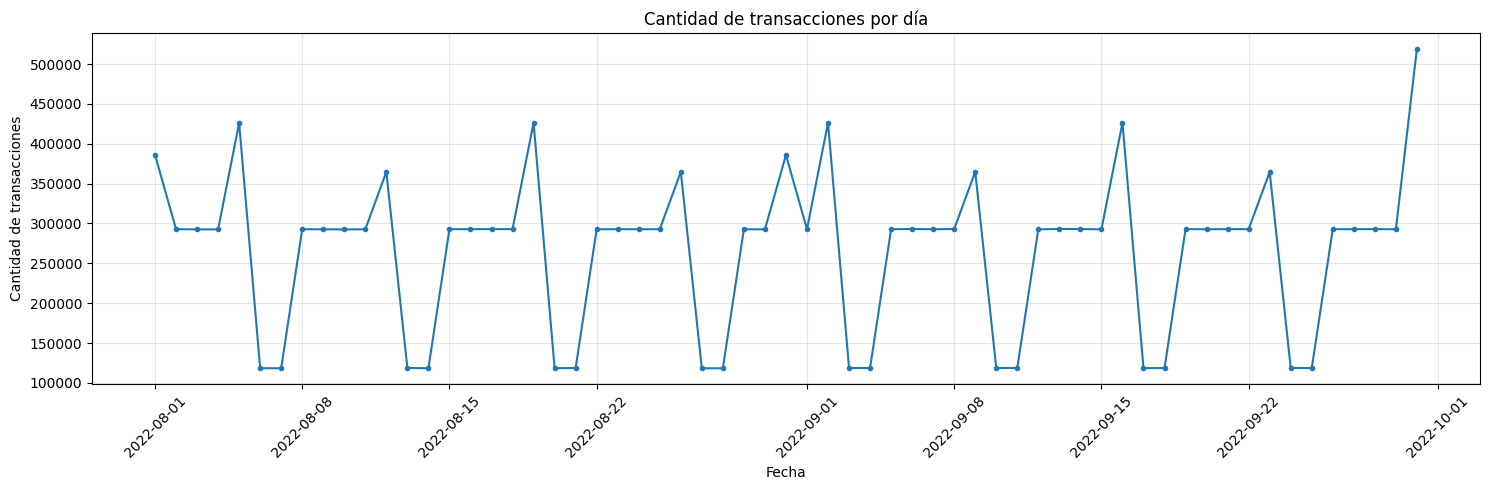

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    df_diario["fecha_dia"],
    df_diario["transacciones"],
    marker="o",
    markersize=3
)

plt.title("Cantidad de transacciones por día")
plt.xlabel("Fecha")
plt.ylabel("Cantidad de transacciones")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

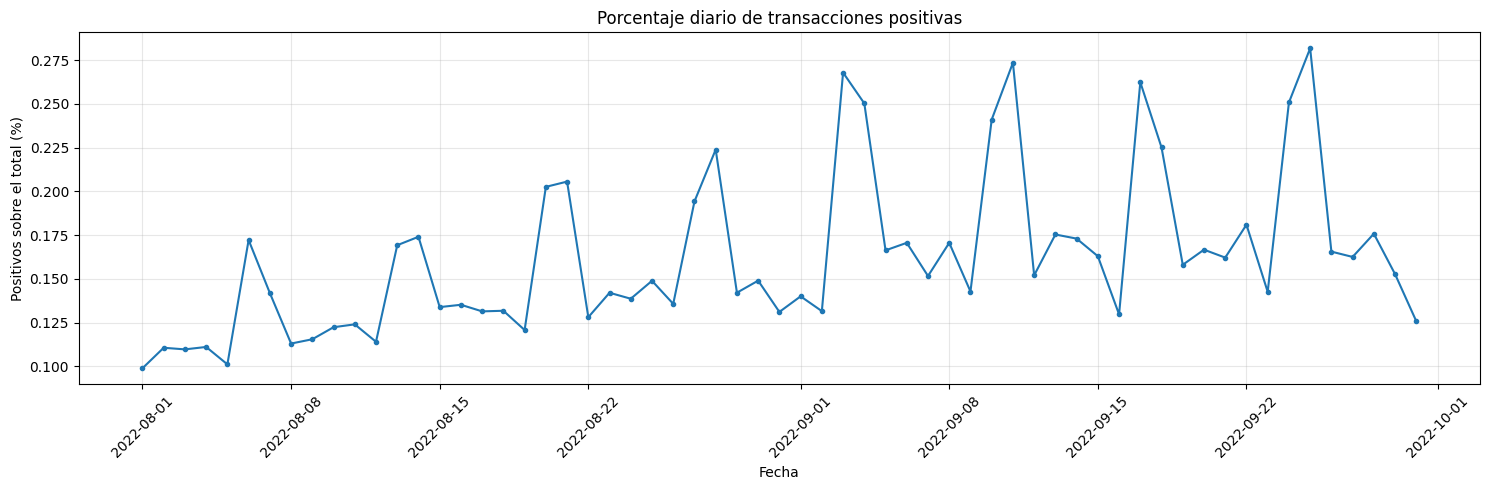

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    df_diario["fecha_dia"],
    df_diario["tasa_positiva_pct"],
    marker="o",
    markersize=3
)

plt.title("Porcentaje diario de transacciones positivas")
plt.xlabel("Fecha")
plt.ylabel("Positivos sobre el total (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ---------------------------------------------------------
# Comparación de alternativas de split temporal
# ---------------------------------------------------------

fecha_inicio = df_diario["fecha_dia"].min()

alternativas = [
    {"nombre": "20 train / 5 val / resto test",
     "dias_train": 20, "dias_val": 5},

    {"nombre": "30 train / 7 val / resto test",
     "dias_train": 30, "dias_val": 7},

    {"nombre": "40 train / 10 val / resto test",
     "dias_train": 40, "dias_val": 10}
]

resultados = []

for alternativa in alternativas:

    dias_train = alternativa["dias_train"]
    dias_val = alternativa["dias_val"]

    fecha_inicio_val = fecha_inicio + pd.Timedelta(days=dias_train)
    fecha_inicio_test = fecha_inicio + pd.Timedelta(days=dias_train + dias_val)

    condiciones = [
        df_diario["fecha_dia"] < fecha_inicio_val,
        (
            (df_diario["fecha_dia"] >= fecha_inicio_val) &
            (df_diario["fecha_dia"] < fecha_inicio_test)
        ),
        df_diario["fecha_dia"] >= fecha_inicio_test
    ]

    nombres = ["Train", "Validation", "Test"]

    for nombre, condicion in zip(nombres, condiciones):

        periodo = df_diario[condicion]

        total = int(periodo["transacciones"].sum())
        positivos = int(periodo["positivas"].sum())
        negativos = int(periodo["negativas"].sum())

        tasa = positivos / total * 100 if total > 0 else 0

        resultados.append({
            "alternativa": alternativa["nombre"],
            "conjunto": nombre,
            "dias": len(periodo),
            "desde": periodo["fecha_dia"].min(),
            "hasta": periodo["fecha_dia"].max(),
            "transacciones": total,
            "positivas": positivos,
            "negativas": negativos,
            "tasa_positiva_pct": tasa
        })

df_comparacion = pd.DataFrame(resultados)

display(
    df_comparacion.style.format({
        "transacciones": "{:,.0f}",
        "positivas": "{:,.0f}",
        "negativas": "{:,.0f}",
        "tasa_positiva_pct": "{:.5f}%"
    })
)

,alternativa,conjunto,dias,desde,hasta,transacciones,positivas,negativas,tasa_positiva_pct
0,20 train / 5 val / resto test,Train,20,2022-08-01 00:00:00,2022-08-20 00:00:00,"5,416,088","6,682","5,409,406",0.12337%
1,20 train / 5 val / resto test,Validation,5,2022-08-21 00:00:00,2022-08-25 00:00:00,"1,289,807","1,877","1,287,930",0.14553%
2,20 train / 5 val / resto test,Test,36,2022-08-26 00:00:00,2022-09-30 00:00:00,"9,602,008","15,755","9,586,253",0.16408%
3,30 train / 7 val / resto test,Train,30,2022-08-01 00:00:00,2022-08-30 00:00:00,"7,892,679","10,401","7,882,278",0.13178%
4,30 train / 7 val / resto test,Validation,7,2022-08-31 00:00:00,2022-09-06 00:00:00,"1,928,309","3,079","1,925,230",0.15967%
5,30 train / 7 val / resto test,Test,24,2022-09-07 00:00:00,2022-09-30 00:00:00,"6,486,915","10,834","6,476,081",0.16701%
6,40 train / 10 val / resto test,Train,40,2022-08-01 00:00:00,2022-09-09 00:00:00,"10,771,669","14,945","10,756,724",0.13874%
7,40 train / 10 val / resto test,Validation,10,2022-09-10 00:00:00,2022-09-19 00:00:00,"2,365,324","4,148","2,361,176",0.17537%
8,40 train / 10 val / resto test,Test,11,2022-09-20 00:00:00,2022-09-30 00:00:00,"3,170,910","5,221","3,165,689",0.16465%


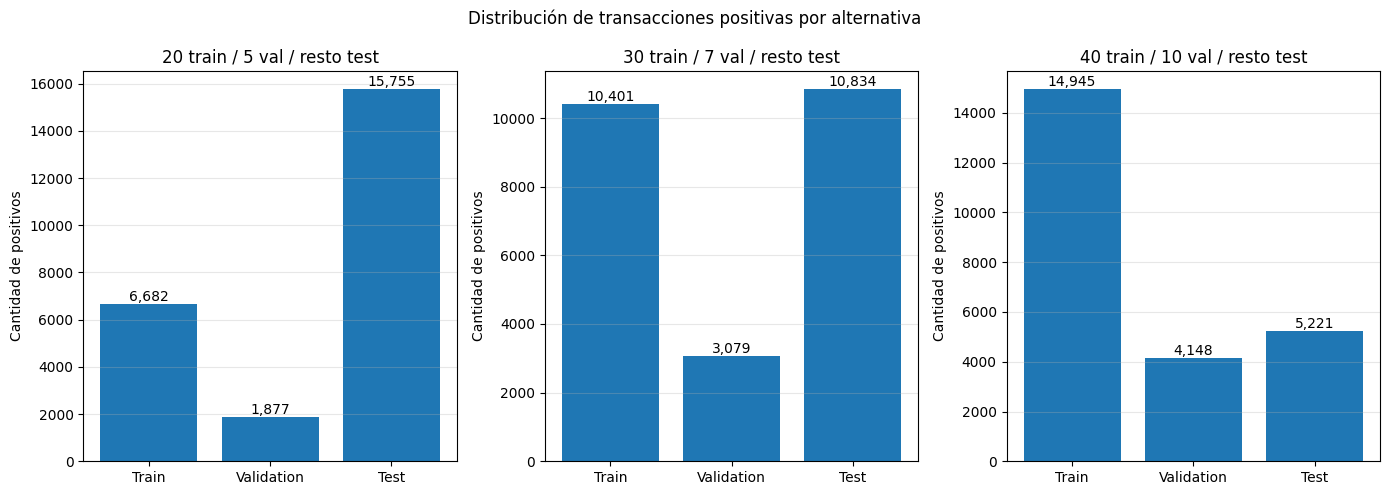

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, alternativa in zip(
    axes,
    df_comparacion["alternativa"].unique()
):

    datos = df_comparacion[
        df_comparacion["alternativa"] == alternativa
    ]

    ax.bar(
        datos["conjunto"],
        datos["positivas"]
    )

    ax.set_title(alternativa)
    ax.set_ylabel("Cantidad de positivos")
    ax.grid(axis="y", alpha=0.3)

    for i, valor in enumerate(datos["positivas"]):
        ax.text(i, valor, f"{valor:,.0f}", ha="center", va="bottom")

plt.suptitle("Distribución de transacciones positivas por alternativa")
plt.tight_layout()
plt.show()

Como vemos en los graficos y tablas, los tres escenarios tienen una cantidad razonable de positivos, aunque la division de 30 train / 7 val / resto test consideramos la mejor ya que por un lado, respecto al de 20 dias, aumenta aproximadamente un 70% los positivos de entrenamiento, y esto es una mejora importante para un problema tan desbalanceado. Además, la alternativa de 40/10/11 no es tan atractiva ya que solamente quedan 11 días y 5.221 positivos.
En cambio, 30/7/24 conserva 24 días y 10.834 positivos, lo que permite evaluar el comportamiento del modelo sobre un período temporal más extenso.

Por lo tanto se elije la divison de 30 días / 7 días / 24 días por las siguiente razones
- Entrenamiento suficientemente extenso para capturar patrones de comportamiento.

- Validation con suficientes casos positivos para seleccionar modelos y umbrales.

- Test con casi un mes de información futura, manteniendo una cantidad considerable de positivos.

- Separación estrictamente cronológica, evitando que el modelo aprenda de información futura.

## **Comprobar si todos los días hay transacciones de todos los medios de pago**

In [ ]:
# Cantidad de transacciones por día y medio de pago
trx_por_dia_formato = (
    df_3m
    .filter(
        F.col("fecha").isNotNull()
        & F.col("Payment Format").isNotNull()
    )
    .groupBy("fecha", "Payment Format")
    .agg(F.count("*").alias("cantidad_trx"))
    .orderBy("fecha", "Payment Format")
)

trx_por_dia_formato.show(100, truncate=False)

+----------+--------------+------------+
|fecha     |Payment Format|cantidad_trx|
+----------+--------------+------------+
|2022-08-01|ACH           |15683       |
|2022-08-01|Bitcoin       |5278        |
|2022-08-01|Cash          |62851       |
|2022-08-01|Cheque        |164398      |
|2022-08-01|Credit Card   |105487      |
|2022-08-01|Reinvestment  |26834       |
|2022-08-01|Wire          |5659        |
|2022-08-02|ACH           |11589       |
|2022-08-02|Bitcoin       |4360        |
|2022-08-02|Cash          |48375       |
|2022-08-02|Cheque        |135938      |
|2022-08-02|Credit Card   |88357       |
|2022-08-02|Wire          |4246        |
|2022-08-03|ACH           |11331       |
|2022-08-03|Bitcoin       |4360        |
|2022-08-03|Cash          |48375       |
|2022-08-03|Cheque        |135886      |
|2022-08-03|Credit Card   |88395       |
|2022-08-03|Wire          |4246        |
|2022-08-04|ACH           |11328       |
|2022-08-04|Bitcoin       |4360        |
|2022-08-04|Cash

## **Comparación de cinco modelos para scoring de transacciones**

El objetivo común es predecir la etiqueta binaria `label` (lavado sí/no) y obtener para cada transacción un score de riesgo. Se comparan **XGBoost, LSTM, GAT, GraphSAGE y STA-GT sin Transformer**.

Todos los modelos utilizan las mismas transacciones, variables de entrada y particiones temporales:
- **Train:** primeros 30 días calendario del período.
- **Validación:** los 7 días calendario inmediatamente posteriores.
- **Test:** todo el período restante.

La validación se necesita para early stopping, selección del mejor estado y ajuste del umbral. El test queda reservado para la comparación final. Los cortes se anclan a las 00:00 del primer día calendario disponible: train cubre [día 1, día 31), validación [día 31, día 38) y test desde el día 38 hasta el final. Las transacciones de un mismo instante quedan siempre en la misma partición.

Las variables categóricas incluyen `Payment Format`, `Receiving Currency` y `Payment Currency`; además, se incorporan `From Bank` y `To Bank` cuando `INCLUIR_BANCOS = True`. XGBoost utiliza One-Hot Encoding explícito. En LSTM y modelos de grafos se utilizan embeddings aprendibles, que equivalen a una proyección de una representación one-hot pero evitan materializar vectores de alta dimensión, especialmente para los bancos.

Las cinco variables continuas comunes se transforman con Min-Max, ajustando el escalador **solamente con train** y aplicándolo luego a train, validación y test. De esta forma se evita fuga de información y todos los modelos reciben las mismas variables numéricas escaladas.

El método 5 es una inspiración del paper Transaction Fraud Detection via Spatial-Temporal-Aware Graph Transformer pero se omite el transformer.  Conserva la codificación temporal, la agregación heterogénea por relaciones, la atención entre relaciones y la fusión entre capas del STA-GT.


In [ ]:
import torch

pyt_version = torch.__version__.split('+')[0]
print(f"Versión de PyTorch activa: {pyt_version}")

# Instalación usando pip (solo torch-geometric, ya que las extensiones C++ fallan al compilar)
print("Instalando PyG...")
!pip install -q torch-geometric

import random
import math
import numpy as np
import torch.nn as nn
import torch.nn.functional as TF
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    precision_score, recall_score, f1_score
)

# Importar PyTorch Geometric para validar que funciona correctamente
from torch_geometric.data import Data
from torch_geometric.loader import NeighborLoader
from torch_geometric.nn import SAGEConv, GATConv

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Optimizado para exprimir la VRAM de una GPU A100
BATCH_SIZE = 32768        # Antes: 16384
NUM_NEIGHBORS = [5, 3]
SEQ_LEN = 8
TABULAR_BATCH_SIZE = 16384 # Antes: 8192
print('Device:', device)
print('¡PyTorch Geometric importado correctamente!')



Versión de PyTorch activa: 2.14.1
Instalando PyG...
Device: cuda
¡PyTorch Geometric importado correctamente!


In [ ]:

from pyspark.sql import Window
from pyspark.sql.types import LongType, StructField, StructType
from pyspark.ml.feature import StringIndexer
from pyspark.storagelevel import StorageLevel

# -------------------------------------------------------------------
# 1. Preparación y validación de las transacciones
# -------------------------------------------------------------------
df_graph_full = (
    df_3m
    .withColumn('Timestamp', F.to_timestamp(F.col('Timestamp')))
    .withColumn('label', F.expr('try_cast(`Is Laundering` AS INT)'))
    .withColumn(
        'amount_received_num',
        F.expr("try_cast(regexp_replace(`Amount Received`, ',', '') AS DOUBLE)")
    )
    .withColumn(
        'amount_paid_num',
        F.expr("try_cast(regexp_replace(`Amount Paid`, ',', '') AS DOUBLE)")
    )
    .withColumn('src', F.concat_ws('::', F.col('From Bank'), F.col('Account2')))
    .withColumn('dst', F.concat_ws('::', F.col('To Bank'), F.col('Account4')))
    .withColumn('timestamp_unix', F.unix_timestamp('Timestamp').cast('long'))
)

filas_invalidas = df_graph_full.filter(
    F.col('label').isNull() | (~F.col('label').isin(0, 1)) |
    F.col('Timestamp').isNull() |
    F.col('amount_received_num').isNull() |
    F.col('amount_paid_num').isNull() |
    (F.col('amount_received_num') < 0) |
    (F.col('amount_paid_num') < 0) |
    F.col('src').isNull() | F.col('dst').isNull() |
    (F.trim('src') == '') | (F.trim('dst') == '') |
    F.col('From Bank').isNull() | (F.trim(F.col('From Bank')) == '') |
    F.col('Account2').isNull() | (F.trim(F.col('Account2')) == '') |
    F.col('To Bank').isNull() | (F.trim(F.col('To Bank')) == '') |
    F.col('Account4').isNull() | (F.trim(F.col('Account4')) == '')
).count()

if filas_invalidas:
    raise ValueError(
        f'Hay {filas_invalidas} filas inválidas; corregilas antes de construir el grafo.'
    )

conteos_etiqueta = {
    int(row['label']): int(row['count'])
    for row in df_graph_full.groupBy('label').count().collect()
}

if any(conteos_etiqueta.get(clase, 0) < 10 for clase in (0, 1)):
    raise ValueError(
        f'Se requieren al menos 10 transacciones de cada clase; conteos: {conteos_etiqueta}'
    )

# -------------------------------------------------------------------
# 2. Split temporal por días calendario
# -------------------------------------------------------------------
# Se reservan los primeros 30 días para desarrollo/entrenamiento,
# los 7 días siguientes para validación y todo el resto para test.
# La validación es necesaria para early stopping y ajuste de umbral.
from datetime import timedelta

inicio_periodo = df_graph_full.agg(
    F.min('Timestamp').alias('inicio')
).first()['inicio']

fin_periodo = df_graph_full.agg(
    F.max('Timestamp').alias('fin')
).first()['fin']

# Anclar los cortes a la medianoche del primer día calendario, no a la hora
# exacta de la primera transacción (que podría no ser 00:00).
from datetime import datetime, time as datetime_time
inicio_dia = datetime.combine(inicio_periodo.date(), datetime_time.min)
corte_train = inicio_dia + timedelta(days=30)  # 30 días completos
corte_val = corte_train + timedelta(days=7)    # 7 días completos

if fin_periodo <= corte_val:
    raise ValueError(
        'El período disponible no alcanza para usar 30 días de train, '
        '7 días de validación y un período posterior de test.'
    )

base = (
    df_graph_full
    .withColumn(
        'split',
        F.when(F.col('Timestamp') < F.lit(corte_train), 'train')
         .when(F.col('Timestamp') < F.lit(corte_val), 'val')
         .otherwise('test')
    )
)

# Verificar que cada partición tenga ambas clases.
conteos_split = {
    (row['split'], int(row['label'])): int(row['count'])
    for row in base.groupBy('split', 'label').count().collect()
}

for nombre_split in ('train', 'val', 'test'):
    for clase in (0, 1):
        cantidad = conteos_split.get((nombre_split, clase), 0)
        if cantidad < 10:
            raise ValueError(
                f'El split {nombre_split} tiene {cantidad} transacciones '
                f'de la clase {clase}. Revisá la duración de validación '
                'o la distribución temporal de las etiquetas.'
            )

orden_split = (
    F.when(F.col('split') == 'train', 0)
     .when(F.col('split') == 'val', 1)
     .otherwise(2)
)

resumen_split = (
    base.groupBy('split')
    .agg(
        F.count('*').alias('transacciones'),
        F.min('Timestamp').alias('desde'),
        F.max('Timestamp').alias('hasta'),
        F.sum(F.when(F.col('label') == 1, 1).otherwise(0)).alias('positivas'),
        F.sum(F.when(F.col('label') == 0, 1).otherwise(0)).alias('negativas'),
        F.avg(F.col('label').cast('double')).alias('tasa_positiva')
    )
    .orderBy(orden_split)
)

print('Primera transacción:', inicio_periodo)
print('Inicio calendario:', inicio_dia)
print('Train (30 días): desde', inicio_dia, 'hasta antes de', corte_train)
print('Validación (7 días): desde', corte_train, 'hasta antes de', corte_val)
print('Test: desde:', corte_val, 'hasta:', fin_periodo)
resumen_split.show(truncate=False)

# -------------------------------------------------------------------
# 3. Codificación categórica: ajustar SOLO con train
# -------------------------------------------------------------------
# Activar/desactivar esta opción permite hacer una prueba de ablación:
# True  -> todos los modelos reciben From Bank y To Bank.
# False -> se usan solamente las tres categorías originales.
INCLUIR_BANCOS = True

columnas_categoricas_base = [
    'Payment Format',
    'Receiving Currency',
    'Payment Currency'
]
columnas_codificadas_base = [
    'cat_payment_format',
    'cat_receiving_currency',
    'cat_payment_currency'
]

columnas_categoricas_bancos = ['From Bank', 'To Bank']
columnas_codificadas_bancos = ['cat_from_bank', 'cat_to_bank']

columnas_categoricas = columnas_categoricas_base.copy()
columnas_codificadas = columnas_codificadas_base.copy()

if INCLUIR_BANCOS:
    columnas_categoricas += columnas_categoricas_bancos
    columnas_codificadas += columnas_codificadas_bancos

indexador = StringIndexer(
    inputCols=columnas_categoricas,
    outputCols=columnas_codificadas,
    handleInvalid='keep'
)

# Evita fuga de información: el vocabulario se aprende únicamente con train.
indexador_modelo = indexador.fit(base.filter(F.col('split') == 'train'))
base = indexador_modelo.transform(base)

print('Variables categóricas utilizadas:', columnas_categoricas)
print('Se incluyen bancos:', INCLUIR_BANCOS)

# Variables numéricas derivadas.
base = (
    base
    .withColumn(
        'feature_amount_received',
        F.log1p(F.greatest(F.col('amount_received_num'), F.lit(0.0))).cast('float')
    )
    .withColumn(
        'feature_amount_paid',
        F.log1p(F.greatest(F.col('amount_paid_num'), F.lit(0.0))).cast('float')
    )
    .withColumn(
        'feature_hour',
        (F.hour('Timestamp').cast('float') / F.lit(23.0)).cast('float')
    )
    .withColumn(
        'feature_weekday',
        ((F.dayofweek('Timestamp').cast('float') - F.lit(1.0)) / F.lit(6.0)).cast('float')
    )
)

# -------------------------------------------------------------------
# 4. Asignación de IDs compactos a las transacciones
# -------------------------------------------------------------------
filas_modelo = (
    base.select(
        F.col('src').cast('string').alias('src'),
        F.col('dst').cast('string').alias('dst'),
        F.col('Timestamp').alias('timestamp'),
        F.col('timestamp_unix').cast('long').alias('timestamp_unix'),
        F.col('label').cast('long').alias('label'),
        F.col('split'),
        F.col('feature_amount_received'),
        F.col('feature_amount_paid'),
        F.col('feature_hour'),
        F.col('feature_weekday'),
        *[F.col(c).cast('int').alias(c) for c in columnas_codificadas]
    )
    .persist(StorageLevel.MEMORY_AND_DISK)
)

num_nodes = filas_modelo.count()

# zipWithIndex asigna IDs 0..N-1 de forma distribuida, sin collect() ni Pandas.
filas_con_id = filas_modelo.rdd.zipWithIndex().map(
    lambda par: (int(par[1]),) + tuple(par[0])
)

nodos = spark.createDataFrame(
    filas_con_id,
    StructType(
        [StructField('node_id', LongType(), False)] +
        list(filas_modelo.schema.fields)
    )
).persist(StorageLevel.MEMORY_AND_DISK)

if nodos.count() != num_nodes:
    raise RuntimeError(
        'No coincide la cantidad de nodos antes y después de asignar IDs.'
    )

filas_modelo.unpersist()

# -------------------------------------------------------------------
# 5. Historial temporal por cuenta de origen para LSTM
# -------------------------------------------------------------------
# La secuencia se ordena cronológicamente por cuenta.
# Incluye la transacción actual y hasta SEQ_LEN - 1 transacciones anteriores.
# Una transacción representativa (menor node_id) por cuenta e instante.
# Así no se inventa un orden temporal entre transacciones simultáneas.
marcas_tiempo_origen = (
    nodos.groupBy('src', 'timestamp')
    .agg(F.min('node_id').alias('representative_node'))
)
ventana_origen = Window.partitionBy('src').orderBy('timestamp')
historial_marcas = marcas_tiempo_origen
for lag in range(1, SEQ_LEN):
    historial_marcas = historial_marcas.withColumn(
        f'previous_{lag}', F.lag('representative_node', lag).over(ventana_origen)
    )
# Todas las transacciones simultáneas de una cuenta comparten el mismo
# contexto histórico anterior; la transacción actual se agrega al final luego.
historial = (
    nodos.select('node_id', 'src', 'timestamp')
    .join(historial_marcas, ['src', 'timestamp'], 'left')
    .select('node_id', *[f'previous_{lag}' for lag in range(1, SEQ_LEN)])
)

# -------------------------------------------------------------------
# 6. Grafo temporal dirigido: pasado -> presente
# -------------------------------------------------------------------
# Cada arista va desde una transacción anterior hacia la transacción actual.
# No agregamos la arista inversa: así, al predecir un nodo, NeighborLoader
# recibe contexto histórico y no puede propagar información desde el futuro.
eventos = (
    nodos.select(
        F.col('src').alias('account'), 'node_id', 'timestamp',
        F.lit(0).alias('role')
    )
    .unionByName(
        nodos.select(
            F.col('dst').alias('account'), 'node_id', 'timestamp',
            F.lit(1).alias('role')
        )
    )
    .filter(F.col('account').isNotNull() & (F.trim('account') != ''))
    .dropDuplicates(['account', 'node_id', 'role'])
)

# Colapsar cada instante por cuenta a un representante determinista.
# Se conecta el representante del instante anterior con todos los eventos
# del instante actual. Nunca se crean aristas entre eventos simultáneos.
ventana_evento = Window.partitionBy('account', 'timestamp').orderBy('node_id', 'role')
representantes = (
    eventos.withColumn('rn', F.row_number().over(ventana_evento))
    .filter(F.col('rn') == 1)
    .select(
        'account', 'timestamp',
        F.col('node_id').alias('previous_node'),
        F.col('role').alias('previous_role')
    )
)
ventana_instantes = Window.partitionBy('account').orderBy('timestamp')
instantes_con_anterior = representantes.withColumn(
    'previous_timestamp', F.lag('timestamp').over(ventana_instantes)
)
instantes_con_anterior = instantes_con_anterior.withColumn(
    'previous_node',
    F.col('previous_node')
)

actuales = eventos.alias('actual')
previos = representantes.alias('previo')
aristas = (
    actuales
    .join(
        instantes_con_anterior.alias('grupo_actual'),
        (F.col('actual.account') == F.col('grupo_actual.account')) &
        (F.col('actual.timestamp') == F.col('grupo_actual.timestamp')),
        'inner'
    )
    .filter(F.col('grupo_actual.previous_timestamp').isNotNull())
    .join(
        previos,
        (F.col('grupo_actual.account') == F.col('previo.account')) &
        (F.col('grupo_actual.previous_timestamp') == F.col('previo.timestamp')),
        'inner'
    )
    .select(
        F.col('previo.previous_node').alias('src_id'),
        F.col('actual.node_id').alias('dst_id'),
        F.when((F.col('previo.previous_role') == 0) & (F.col('actual.role') == 0), 0)
         .when((F.col('previo.previous_role') == 1) & (F.col('actual.role') == 1), 1)
         .when((F.col('previo.previous_role') == 0) & (F.col('actual.role') == 1), 2)
         .otherwise(3).alias('relation_id')
    )
    .filter(F.col('src_id') != F.col('dst_id'))
    .dropDuplicates(['src_id', 'dst_id', 'relation_id'])
    .persist(StorageLevel.MEMORY_AND_DISK)
)

num_edges = aristas.count()

if num_edges == 0:
    raise ValueError(
        'El grafo temporal no tiene aristas; revisá las cuentas y timestamps.'
    )

# -------------------------------------------------------------------
# 7. Feature histórica de vecinos positivos, sin usar etiquetas futuras
# -------------------------------------------------------------------
# Solo se consideran nodos positivos de train.
# Como las aristas apuntan del pasado al presente, el conteo de cada nodo
# incluye únicamente vecinos positivos de train que ocurrieron antes.
positivos_train = (
    nodos
    .filter((F.col('split') == 'train') & (F.col('label') == 1))
    .select(F.col('node_id').alias('positive_train_node_id'))
)

conteo_vecinos = (
    aristas.alias('e')
    .join(
        positivos_train.alias('p'),
        F.col('e.src_id') == F.col('p.positive_train_node_id'),
        'inner'
    )
    .groupBy(F.col('e.dst_id').alias('node_id'))
    .agg(
        F.countDistinct(F.col('e.src_id')).alias('neighbor_laundering_count')
    )
)

nodos_con_vecinos = (
    nodos
    .join(conteo_vecinos, 'node_id', 'left')
    .fillna({'neighbor_laundering_count': 0})
    .persist(StorageLevel.MEMORY_AND_DISK)
)

nodos_con_vecinos.count()
nodos.unpersist()
nodos = nodos_con_vecinos

# -------------------------------------------------------------------
# 8. Materialización de matrices para PyTorch
# -------------------------------------------------------------------
# Se utiliza streaming de particiones Spark; no se descartan ni muestrean filas.
history_index = np.full((num_nodes, SEQ_LEN), -1, dtype=np.int32)
history_index[:, -1] = np.arange(num_nodes, dtype=np.int32)

columnas_historial = ['node_id'] + [
    f'previous_{lag}' for lag in range(1, SEQ_LEN)
]

for row in historial.select(*columnas_historial).toLocalIterator():
    node_id = int(row['node_id'])
    for lag in range(1, SEQ_LEN):
        previous_node = row[f'previous_{lag}']
        if previous_node is not None:
            history_index[node_id, -1 - lag] = int(previous_node)

x_np = np.empty((num_nodes, 5), dtype=np.float32)
time_hours_np = np.empty(num_nodes, dtype=np.float32)
cat_np = np.empty((num_nodes, len(columnas_codificadas)), dtype=np.int64)
y_np = np.empty(num_nodes, dtype=np.int64)
split_np = np.empty(num_nodes, dtype=np.int8)

mapa_split = {'train': 0, 'val': 1, 'test': 2}

columnas_nodo = [
    'node_id',
    'timestamp_unix',
    'feature_amount_received',
    'feature_amount_paid',
    'feature_hour',
    'feature_weekday',
    'neighbor_laundering_count',
    'label',
    'split',
    *columnas_codificadas
]

for row in nodos.select(*columnas_nodo).toLocalIterator():
    i = int(row['node_id'])

    x_np[i] = [
        float(row['feature_amount_received'] or 0.0),
        float(row['feature_amount_paid'] or 0.0),
        float(row['feature_hour'] or 0.0),
        float(row['feature_weekday'] or 0.0),
        float(np.log1p(row['neighbor_laundering_count'] or 0))
    ]

    cat_np[i] = [int(row[c]) + 1 for c in columnas_codificadas]
    time_hours_np[i] = float(row['timestamp_unix'] or 0) / 3600.0
    y_np[i] = int(row['label'])
    split_np[i] = mapa_split[row['split']]

# -------------------------------------------------------------------
# 8.1. Normalización Min-Max de variables continuas
# -------------------------------------------------------------------
# Se ajusta únicamente con train para evitar data leakage.
# Se aplica el mismo escalador a todos los modelos y a las tres particiones.
from sklearn.preprocessing import MinMaxScaler

nombres_features_numericas = [
    'amount_received_log',
    'amount_paid_log',
    'hour',
    'weekday',
    'neighbor_laundering_count_log'
]

scaler_minmax = MinMaxScaler()
scaler_minmax.fit(x_np[split_np == 0])
x_np = scaler_minmax.transform(x_np).astype(np.float32)

print('Min-Max ajustado exclusivamente con train.')
print('Features continuas normalizadas:', nombres_features_numericas)
print('Rango observado en train después de escalar:',
      float(x_np[split_np == 0].min()), 'a',
      float(x_np[split_np == 0].max()))

# Se materializan las aristas dirigidas en CPU; NeighborLoader las muestrea por lotes.
edge_index_np = np.empty((2, num_edges), dtype=np.int64)
edge_type_np = np.empty(num_edges, dtype=np.int64)

for i, row in enumerate(
    aristas.select('src_id', 'dst_id', 'relation_id').toLocalIterator()
):
    edge_index_np[0, i] = int(row['src_id'])
    edge_index_np[1, i] = int(row['dst_id'])
    edge_type_np[i] = int(row['relation_id'])

if i + 1 != num_edges:
    raise RuntimeError(
        f'Esperaba {num_edges} aristas y se recibieron {i + 1}.'
    )

train_mask = torch.from_numpy(split_np == 0)
val_mask = torch.from_numpy(split_np == 1)
test_mask = torch.from_numpy(split_np == 2)

data = Data(
    x=torch.from_numpy(x_np),
    cat=torch.from_numpy(cat_np),
    y=torch.from_numpy(y_np),
    edge_index=torch.from_numpy(edge_index_np),
    edge_type=torch.from_numpy(edge_type_np),
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask
)

print('Variables categóricas codificadas (índices reales desplazados +1; 0 reservado para padding):', columnas_codificadas)
print(
    f'Transacciones/nodos usados: {num_nodes:,} de {num_nodes:,} '
    f'| aristas históricas dirigidas: {num_edges:,}'
)
print(
    f'Máscaras -> train: {int(train_mask.sum()):,}, '
    f'val: {int(val_mask.sum()):,}, test: {int(test_mask.sum()):,}'
)
print(
    f'Positivas -> train: {int(data.y[train_mask].sum()):,}, '
    f'val: {int(data.y[val_mask].sum()):,}, '
    f'test: {int(data.y[test_mask].sum()):,}'
)

# Desplazar el origen temporal para mejorar la escala de la codificación sinusoidal.
time_hours_np -= time_hours_np.min()

aristas.unpersist()
nodos.unpersist()


Primera transacción: 2022-08-01 00:00:00
Inicio calendario: 2022-08-01 00:00:00
Train (30 días): desde 2022-08-01 00:00:00 hasta antes de 2022-08-31 00:00:00
Validación (7 días): desde 2022-08-31 00:00:00 hasta antes de 2022-09-07 00:00:00
Test: desde: 2022-09-07 00:00:00 hasta: 2022-09-30 23:59:00
+-----+-------------+-------------------+-------------------+---------+---------+---------------------+
|split|transacciones|desde              |hasta              |positivas|negativas|tasa_positiva        |
+-----+-------------+-------------------+-------------------+---------+---------+---------------------+
|train|7892679      |2022-08-01 00:00:00|2022-08-30 23:59:00|10401    |7882278  |0.0013178034986599607|
|val  |1928309      |2022-08-31 00:00:00|2022-09-06 23:59:00|3079     |1925230  |0.0015967357928630733|
|test |6486915      |2022-09-07 00:00:00|2022-09-30 23:59:00|10834    |6476081  |0.0016701313336154398|
+-----+-------------+-------------------+-------------------+---------+-----

DataFrame[node_id: bigint, src: string, dst: string, timestamp: timestamp, timestamp_unix: bigint, label: bigint, split: string, feature_amount_received: float, feature_amount_paid: float, feature_hour: float, feature_weekday: float, cat_payment_format: int, cat_receiving_currency: int, cat_payment_currency: int, cat_from_bank: int, cat_to_bank: int, neighbor_laundering_count: bigint]

## Preparacion comun de evaluacion y grafos

Se definen las particiones, las metricas compartidas y las utilidades de entrenamiento que usan los modelos de grafos. No son un metodo adicional.


In [ ]:
train_ids = np.flatnonzero(split_np == 0)
val_ids = np.flatnonzero(split_np == 1)
test_ids = np.flatnonzero(split_np == 2)


def metricas_desde_scores(nombre, scores):
    precision, recall, thresholds = precision_recall_curve(y_np[val_ids], scores[val_ids])
    f1_val = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    threshold = float(thresholds[int(np.argmax(f1_val))]) if len(thresholds) else 0.5
    pred_test = (scores[test_ids] >= threshold).astype(np.int64)
    return {
        'modelo': nombre,
        'AP_val': average_precision_score(y_np[val_ids], scores[val_ids]),
        'AP_test': average_precision_score(y_np[test_ids], scores[test_ids]),
        'ROC_AUC_test': roc_auc_score(y_np[test_ids], scores[test_ids]),
        'precision_test': precision_score(y_np[test_ids], pred_test, zero_division=0),
        'recall_test': recall_score(y_np[test_ids], pred_test, zero_division=0),
        'F1_test': f1_score(y_np[test_ids], pred_test, zero_division=0),
        'umbral_val': threshold
    }

In [ ]:
class _BaseGNNTransacciones(nn.Module):
    def __init__(self, cardinalidades, embedding_dim=8):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(max(2, int(n)), embedding_dim, padding_idx=0) for n in cardinalidades
        ])
        self.dropout = 0.3

    def features(self, batch):
        partes = [batch.x]
        partes.extend(
            embedding(batch.cat[:, i])
            for i, embedding in enumerate(self.embeddings)
        )
        return torch.cat(partes, dim=1)


cardinalidades = [int(data.cat[:, i].max().item()) + 1 for i in range(data.cat.shape[1])]


def predecir_scores(model, input_mask):
    loader = NeighborLoader(
        data,
        input_nodes=input_mask,
        num_neighbors=NUM_NEIGHBORS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=8,
        pin_memory=True
    )
    scores = np.full(num_nodes, np.nan, dtype=np.float32)
    model.eval()
    with torch.no_grad():
        for batch in loader:
            seed_count = int(batch.batch_size)
            node_ids = batch.n_id[:seed_count].cpu().numpy()
            batch = batch.to(device)
            logits = model(batch)[:seed_count]
            scores[node_ids] = logits.softmax(dim=1)[:, 1].cpu().numpy()
    return scores


def entrenar_y_evaluar(nombre, model_class, max_epochs=10, patience=3):
    model = model_class(cardinalidades).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    conteos = torch.bincount(data.y[data.train_mask], minlength=2).float().clamp_min(1)
    pesos = (conteos.sum() / (2 * conteos)).to(device)
    criterion = nn.CrossEntropyLoss(weight=pesos)
    loader_train = NeighborLoader(
        data,
        input_nodes=data.train_mask,
        num_neighbors=NUM_NEIGHBORS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=8,
        pin_memory=True
    )
    mejores_pesos = None
    mejor_ap = -1.0
    sin_mejora = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        losses = []
        for batch in loader_train:
            seed_count = int(batch.batch_size)
            batch = batch.to(device)
            optimizer.zero_grad()
            logits = model(batch)[:seed_count]
            mask_train_batch = batch.train_mask[:seed_count]
            if not torch.any(mask_train_batch):
                continue
            loss = criterion(logits[mask_train_batch], batch.y[:seed_count][mask_train_batch])
            loss.backward()
            optimizer.step()
            losses.append(loss.item())

        val_scores = predecir_scores(model, data.val_mask)
        val_ids = np.flatnonzero(split_np == 1)
        val_ap = average_precision_score(y_np[val_ids], val_scores[val_ids])
        mean_loss = float(np.mean(losses)) if losses else float('nan')
        print(f'{nombre} | epoch {epoch:02d} | loss={mean_loss:.4f} | val AP={val_ap:.4f}')
        if val_ap > mejor_ap:
            mejor_ap = val_ap
            mejores_pesos = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            sin_mejora = 0
        else:
            sin_mejora += 1
        if sin_mejora >= patience:
            break

    if mejores_pesos is None:
        raise RuntimeError(f'{nombre}: no se guardó ningún estado entrenado.')
    model.load_state_dict(mejores_pesos)
    model.to(device)
    scores_all = predecir_scores(model, torch.ones(num_nodes, dtype=torch.bool))

    val_ids = np.flatnonzero(split_np == 1)
    test_ids = np.flatnonzero(split_np == 2)
    precision, recall, thresholds = precision_recall_curve(y_np[val_ids], scores_all[val_ids])
    f1_val = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    threshold = float(thresholds[int(np.argmax(f1_val))]) if len(thresholds) else 0.5
    pred_test = (scores_all[test_ids] >= threshold).astype(np.int64)
    metricas = {
        'modelo': nombre,
        'AP_test': average_precision_score(y_np[test_ids], scores_all[test_ids]),
        'ROC_AUC_test': roc_auc_score(y_np[test_ids], scores_all[test_ids]),
        'precision_test': precision_score(y_np[test_ids], pred_test, zero_division=0),
        'recall_test': recall_score(y_np[test_ids], pred_test, zero_division=0),
        'F1_test': f1_score(y_np[test_ids], pred_test, zero_division=0),
        'umbral_val': threshold
    }
    return scores_all, metricas


## Metodo 1 de 5: XGBoost

---

Modelo tabular con variables numericas y categoricas. Incluye `From Bank` y `To Bank` como categorías cuando `INCLUIR_BANCOS = True`. El entrenamiento usa la particion train y la validacion para early stopping; produce un score para cada transaccion.

In [ ]:
from scipy.sparse import csr_matrix, hstack
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier


# XGBoost: variables continuas normalizadas + One-Hot Encoding de categorías.
# El encoder se ajusta únicamente con train; categorías nuevas se ignoran.
encoder_xgb = OneHotEncoder(handle_unknown='ignore', dtype=np.float32)
encoder_xgb.fit(cat_np[train_ids])
cat_all = encoder_xgb.transform(cat_np)
X_xgb = hstack([csr_matrix(x_np), cat_all], format='csr', dtype=np.float32)
positivos_train = int(y_np[train_ids].sum())
negativos_train = len(train_ids) - positivos_train
modelo_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='aucpr',
    tree_method='hist',
    device='cuda', # <--- Aceleración por GPU activada
    scale_pos_weight=negativos_train / max(positivos_train, 1),
    early_stopping_rounds=20,
    random_state=SEED
)
modelo_xgb.fit(
    X_xgb[train_ids], y_np[train_ids],
    eval_set=[(X_xgb[val_ids], y_np[val_ids])],
    verbose=50
)
scores_xgb = modelo_xgb.predict_proba(X_xgb)[:, 1].astype(np.float32)
metricas_xgb = metricas_desde_scores('XGBoost', scores_xgb)
print('XGBoost AP test:', round(metricas_xgb['AP_test'], 5))


[0]	validation_0-aucpr:0.03334
[50]	validation_0-aucpr:0.09473
[100]	validation_0-aucpr:0.11755
[150]	validation_0-aucpr:0.11953
[200]	validation_0-aucpr:0.12080
[250]	validation_0-aucpr:0.12036
[258]	validation_0-aucpr:0.12035
XGBoost AP test: 0.1106


## Metodo 2 de 5: LSTM

---

Modelo secuencial que procesa hasta ocho transacciones de la cuenta de origen, ordenadas cronologicamente. Para cada transaccion de la secuencia utiliza sus variables numericas y categoricas, incluyendo los bancos de origen y destino cuando `INCLUIR_BANCOS = True`.

In [ ]:
# LSTM por cuenta de origen: los IDs faltantes representan padding al inicio de la historia.
class LSTMTransacciones(nn.Module):
    def __init__(self, cardinalidades, embedding_dim=8, hidden_dim=64):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(max(2, int(n) + 1), embedding_dim, padding_idx=0) for n in cardinalidades
        ])
        self.lstm = nn.LSTM(5 + embedding_dim * len(cardinalidades), hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.output = nn.Linear(hidden_dim, 2)

    def forward(self, x_seq, cat_seq):
        embeddings = [embedding(cat_seq[:, :, i]) for i, embedding in enumerate(self.embeddings)]
        sequence = torch.cat([x_seq, *embeddings], dim=2)
        _, (hidden, _) = self.lstm(sequence)
        return self.output(self.dropout(hidden[-1]))


cardinalidades_lstm = [int(cat_np[:, i].max()) + 1 for i in range(cat_np.shape[1])]


def iterar_lotes_lstm(node_ids, shuffle=False):
    ids = np.random.permutation(node_ids) if shuffle else node_ids
    for start in range(0, len(ids), TABULAR_BATCH_SIZE):
        batch_ids = ids[start:start + TABULAR_BATCH_SIZE]
        history_ids = history_index[batch_ids]
        valid = history_ids >= 0
        x_batch = np.zeros((len(batch_ids), SEQ_LEN, x_np.shape[1]), dtype=np.float32)
        cat_batch = np.zeros((len(batch_ids), SEQ_LEN, cat_np.shape[1]), dtype=np.int64)
        row_idx, time_idx = np.nonzero(valid)
        prior_ids = history_ids[valid].astype(np.int64)
        x_batch[row_idx, time_idx] = x_np[prior_ids]
        cat_batch[row_idx, time_idx] = cat_np[prior_ids]
        yield (
            torch.from_numpy(x_batch).to(device),
            torch.from_numpy(cat_batch).to(device),
            torch.from_numpy(y_np[batch_ids]).long().to(device),
            batch_ids
        )


modelo_lstm = LSTMTransacciones(cardinalidades_lstm).to(device)
conteos_lstm = np.bincount(y_np[train_ids], minlength=2).astype(np.float32)
pesos_lstm = torch.tensor(
    conteos_lstm.sum() / (2 * np.maximum(conteos_lstm, 1)), dtype=torch.float32, device=device
)
criterio_lstm = nn.CrossEntropyLoss(weight=pesos_lstm)
optimizador_lstm = torch.optim.Adam(modelo_lstm.parameters(), lr=0.001)
mejor_ap_lstm = -1.0
mejor_estado_lstm = None
sin_mejora_lstm = 0
EPOCHS_LSTM = 5
PATIENCE_LSTM = 2

for epoch in range(1, EPOCHS_LSTM + 1):
    modelo_lstm.train()
    losses = []
    for x_batch, cat_batch, y_batch, _ in iterar_lotes_lstm(train_ids, shuffle=True):
        optimizador_lstm.zero_grad()
        logits = modelo_lstm(x_batch, cat_batch)
        loss = criterio_lstm(logits, y_batch)
        loss.backward()
        optimizador_lstm.step()
        losses.append(loss.item())

    modelo_lstm.eval()
    val_scores_lstm = np.empty(len(val_ids), dtype=np.float32)
    cursor = 0
    with torch.no_grad():
        for x_batch, cat_batch, _, _ in iterar_lotes_lstm(val_ids):
            batch_scores = modelo_lstm(x_batch, cat_batch).softmax(dim=1)[:, 1].cpu().numpy()
            val_scores_lstm[cursor:cursor + len(batch_scores)] = batch_scores
            cursor += len(batch_scores)
    ap_val = average_precision_score(y_np[val_ids], val_scores_lstm)
    print(f'LSTM | epoch {epoch} | loss={np.mean(losses):.4f} | val AP={ap_val:.5f}')
    if ap_val > mejor_ap_lstm:
        mejor_ap_lstm = ap_val
        mejor_estado_lstm = {k: v.detach().cpu().clone() for k, v in modelo_lstm.state_dict().items()}
        sin_mejora_lstm = 0
    else:
        sin_mejora_lstm += 1
    if sin_mejora_lstm >= PATIENCE_LSTM:
        break

if mejor_estado_lstm is None:
    raise RuntimeError('LSTM no obtuvo un estado entrenado.')
modelo_lstm.load_state_dict(mejor_estado_lstm)
modelo_lstm.to(device)
modelo_lstm.eval()
scores_lstm = np.empty(num_nodes, dtype=np.float32)
cursor = 0
with torch.no_grad():
    for x_batch, cat_batch, _, batch_ids in iterar_lotes_lstm(np.arange(num_nodes)):
        batch_scores = modelo_lstm(x_batch, cat_batch).softmax(dim=1)[:, 1].cpu().numpy()
        scores_lstm[batch_ids] = batch_scores
        cursor += len(batch_scores)
metricas_lstm = metricas_desde_scores('LSTM', scores_lstm)
print(f"LSTM: scores calculados para {cursor:,} transacciones; test AP={metricas_lstm['AP_test']:.5f}")


LSTM | epoch 1 | loss=0.5645 | val AP=0.03257
LSTM | epoch 2 | loss=0.5282 | val AP=0.05139
LSTM | epoch 3 | loss=0.5151 | val AP=0.07311
LSTM | epoch 4 | loss=0.4939 | val AP=0.08065
LSTM | epoch 5 | loss=0.4787 | val AP=0.08393
LSTM: scores calculados para 16,307,903 transacciones; test AP=0.07918


## Metodo 3 de 5: GAT

Modelo de grafos con atencion sobre los vecinos. Los nodos son transacciones y utiliza el mismo grafo temporal que GraphSAGE y STA-GT. Recibe las variables numericas y categoricas comunes, incluyendo `From Bank` y `To Bank` cuando `INCLUIR_BANCOS = True`. La loss se calcula solo en los nodos de train mediante la mascara correspondiente.

In [ ]:
# Reemplazo de NeighborLoader en PyTorch puro (no requiere pyg-lib ni torch-sparse).
# Pegar en una celda de Colab ANTES de entrenar GAT / GraphSAGE / STA-GT.
import torch
from torch_geometric.data import Data


class NeighborLoader:
    """Muestrea hasta k vecinos ENTRANTES (pasado -> presente) por salto.
    Misma interfaz que la usada en el notebook: batch.batch_size, batch.n_id,
    los seeds quedan primero en n_id."""

    def __init__(self, data, input_nodes, num_neighbors, batch_size,
                 shuffle=False, **kwargs):
        self.data = data
        self.num_neighbors = list(num_neighbors)
        self.batch_size = int(batch_size)
        self.shuffle = shuffle
        if input_nodes.dtype == torch.bool:
            input_nodes = input_nodes.nonzero(as_tuple=False).view(-1)
        self.input_nodes = input_nodes.long()

        n = data.num_nodes if data.num_nodes is not None else data.x.shape[0]
        src, dst = data.edge_index
        orden = torch.argsort(dst)
        self.src_ord = src[orden]
        self.dst_ord = dst[orden]
        self.type_ord = data.edge_type[orden]
        conteo = torch.bincount(dst, minlength=n)
        self.rowptr = torch.cat([torch.zeros(1, dtype=torch.long), conteo.cumsum(0)])
        self.marca = torch.zeros(n, dtype=torch.bool)
        self.mapa = torch.zeros(n, dtype=torch.long)

    def __len__(self):
        return (len(self.input_nodes) + self.batch_size - 1) // self.batch_size

    def __iter__(self):
        ids = self.input_nodes
        if self.shuffle:
            ids = ids[torch.randperm(len(ids))]
        for i in range(0, len(ids), self.batch_size):
            yield self._muestrear(ids[i:i + self.batch_size])

    def _muestrear(self, seeds):
        nodos = seeds
        self.marca[nodos] = True
        frontera = seeds
        aristas = []
        for k in self.num_neighbors:
            ini = self.rowptr[frontera]
            grado = self.rowptr[frontera + 1] - ini
            ok = grado > 0
            ini, grado = ini[ok], grado[ok]
            if len(ini) == 0:
                break
            offs = (torch.rand(len(ini), k) * grado.unsqueeze(1)).long()
            pos = torch.unique((ini.unsqueeze(1) + offs).reshape(-1))
            aristas.append(pos)
            vecinos = torch.unique(self.src_ord[pos])
            nuevos = vecinos[~self.marca[vecinos]]
            self.marca[nuevos] = True
            nodos = torch.cat([nodos, nuevos])
            frontera = nuevos
        self.marca[nodos] = False

        self.mapa[nodos] = torch.arange(len(nodos))
        if aristas:
            pos = torch.unique(torch.cat(aristas))
            edge_index = torch.stack([self.mapa[self.src_ord[pos]],
                                      self.mapa[self.dst_ord[pos]]])
            edge_type = self.type_ord[pos]
        else:
            edge_index = torch.empty((2, 0), dtype=torch.long)
            edge_type = torch.empty(0, dtype=torch.long)

        d = self.data
        batch = Data(x=d.x[nodos], cat=d.cat[nodos], y=d.y[nodos],
                     train_mask=d.train_mask[nodos],
                     edge_index=edge_index, edge_type=edge_type)
        batch.n_id = nodos
        batch.batch_size = len(seeds)
        return batch


In [ ]:
class GATTransacciones(_BaseGNNTransacciones):
    def __init__(self, cardinalidades, hidden_dim=16, heads=4):
        super().__init__(cardinalidades)
        input_dim = 5 + 8 * len(cardinalidades)
        self.conv1 = GATConv(input_dim, hidden_dim, heads=heads, dropout=self.dropout)
        self.conv2 = GATConv(hidden_dim * heads, 2, heads=1, concat=False, dropout=self.dropout)

    def forward(self, batch):
        h = TF.elu(self.conv1(self.features(batch), batch.edge_index))
        h = TF.dropout(h, p=self.dropout, training=self.training)
        return self.conv2(h, batch.edge_index)


scores_gat, metricas_gat = entrenar_y_evaluar('GAT', GATTransacciones)
if np.isnan(scores_gat).any():
    raise RuntimeError('GAT no produjo score para todas las transacciones.')
print(f'GAT: score generado para {len(scores_gat):,} transacciones.')

GAT | epoch 01 | loss=0.6365 | val AP=0.0112
GAT | epoch 02 | loss=0.5974 | val AP=0.0128
GAT | epoch 03 | loss=0.5940 | val AP=0.0144
GAT | epoch 04 | loss=0.5902 | val AP=0.0144
GAT | epoch 05 | loss=0.5907 | val AP=0.0150
GAT | epoch 06 | loss=0.5891 | val AP=0.0151
GAT | epoch 07 | loss=0.5860 | val AP=0.0201
GAT | epoch 08 | loss=0.5865 | val AP=0.0154
GAT | epoch 09 | loss=0.5878 | val AP=0.0178
GAT | epoch 10 | loss=0.5872 | val AP=0.0159
GAT: score generado para 16,307,903 transacciones.


## Metodo 4 de 5: GraphSAGE

Modelo de grafos que agrega informacion de los vecinos. Los nodos son transacciones y utiliza el mismo grafo temporal que GAT y STA-GT. Recibe las variables numericas y categoricas comunes, incluyendo `From Bank` y `To Bank` cuando `INCLUIR_BANCOS = True`. Comparte las mismas particiones y mascaras que GAT.

In [ ]:
class GraphSAGETransacciones(_BaseGNNTransacciones):
    def __init__(self, cardinalidades, hidden_dim=64):
        super().__init__(cardinalidades)
        input_dim = 5 + 8 * len(cardinalidades)
        self.conv1 = SAGEConv(input_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, 2)

    def forward(self, batch):
        h = TF.relu(self.conv1(self.features(batch), batch.edge_index))
        h = TF.dropout(h, p=self.dropout, training=self.training)
        return self.conv2(h, batch.edge_index)


scores_sage, metricas_sage = entrenar_y_evaluar('GraphSAGE', GraphSAGETransacciones)
if np.isnan(scores_sage).any():
    raise RuntimeError('GraphSAGE no produjo score para todas las transacciones.')
print(f'GraphSAGE: score generado para {len(scores_sage):,} transacciones.')

GraphSAGE | epoch 01 | loss=0.5557 | val AP=0.0311
GraphSAGE | epoch 02 | loss=0.5357 | val AP=0.0411
GraphSAGE | epoch 03 | loss=0.5311 | val AP=0.0747
GraphSAGE | epoch 04 | loss=0.5308 | val AP=0.0811
GraphSAGE | epoch 05 | loss=0.5306 | val AP=0.0435
GraphSAGE | epoch 06 | loss=0.5282 | val AP=0.0842
GraphSAGE | epoch 07 | loss=0.5254 | val AP=0.0904
GraphSAGE | epoch 08 | loss=0.5263 | val AP=0.1060
GraphSAGE | epoch 09 | loss=0.5252 | val AP=0.0960
GraphSAGE | epoch 10 | loss=0.5245 | val AP=0.0976
GraphSAGE: score generado para 16,307,903 transacciones.


## Método 5 de 5: STA-GT adaptado al paper, sin Transformer

Esta variante conserva los componentes espaciales y temporales principales del artículo *Transaction Fraud Detection via Spatial-Temporal-Aware Graph Transformer*, pero **elimina el módulo Transformer** para medir qué aporta el aprendizaje local/relacional sin la etapa de atención global.

1. **Embedding de atributos (ecuación 1):** proyección lineal de las variables numéricas y embeddings categóricos, seguida de ReLU. Los embeddings son una forma eficiente de implementar una proyección aprendible de variables one-hot.
2. **Codificación temporal (ecuaciones 2-5):** codificación sinusoidal del timestamp en horas desde el inicio del período y proyección lineal aprendible; se suma al embedding inicial.
3. **Agregación espacial heterogénea (ecuaciones 6-9):** para cada relación se agregan los embeddings de los vecinos y las diferencias entre el nodo central y cada vecino. Una atención específica por nodo pondera las cuatro relaciones según la información que recibe cada transacción.
4. **Fusión entre capas (ecuación 10):** concatenación de las representaciones de las dos capas GNN.
5. **Clasificación (ecuaciones 15-16):** una MLP produce el score y se entrena con Binary Cross-Entropy ponderada para tratar el fuerte desbalance de HI-Large.

**Qué se elimina:** el Transformer del artículo (ecuaciones 11-14), que modela interacciones globales mediante atención multi-cabeza, conexiones residuales, feed-forward y normalización. Sin ese bloque, la clasificación se realiza directamente a partir de la representación fusionada de las dos capas de agregación.

**Adaptaciones para HI-Large:** el dataset no contiene IP, MAC ni identificadores de dispositivos como los del artículo. Se construyen cuatro relaciones dirigidas a partir de cuentas compartidas según el rol origen/destino, conectando el evento representativo del instante anterior con los eventos del instante actual. Las transacciones simultáneas no se ordenan artificialmente. Por lo tanto, es una variante adaptada del componente espacial-temporal de STA-GT y no una reproducción exacta del método completo.

La partición temporal es común a los cinco modelos: 30 días calendario de train, 7 días calendario de validación y el resto para test. Las aristas apuntan del pasado al presente y la loss se calcula exclusivamente sobre semillas de train.


In [ ]:
NUM_RELATIONS_STAGT = 4
# Batch size masivo para STA-GT optimizado para VRAM de la A100
BATCH_SIZE_STAGT = 8192 # Antes: 4096


class STAGTTransaccionesSinTransformer(nn.Module):
    def __init__(self, cardinalidades, hidden_dim=64, num_relations=NUM_RELATIONS_STAGT):
        super().__init__()
        self.num_relations = num_relations
        self.num_layers = 2

        self.embeddings = nn.ModuleList([
            nn.Embedding(max(2, int(n)), 8, padding_idx=0) for n in cardinalidades
        ])
        input_dim = 5 + 8 * len(cardinalidades)

        self.attribute_projection = nn.Linear(input_dim, hidden_dim)
        self.temporal_projection = nn.Linear(hidden_dim, hidden_dim)

        self.relation_combiners = nn.ModuleList([
            nn.ModuleList([
                nn.Linear(hidden_dim * 2, hidden_dim)
                for _ in range(num_relations)
            ])
            for _ in range(self.num_layers)
        ])

        self.relation_score_layers = nn.ModuleList([
            nn.Linear(hidden_dim, hidden_dim)
            for _ in range(self.num_layers)
        ])
        self.relation_queries = nn.ParameterList([
            nn.Parameter(torch.empty(hidden_dim))
            for _ in range(self.num_layers)
        ])
        for query in self.relation_queries:
            nn.init.xavier_uniform_(query.unsqueeze(0))

        self.dropout = nn.Dropout(0.3)
        self.fused_dim = hidden_dim * self.num_layers

        self.classifier = nn.Sequential(
            nn.Linear(self.fused_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, 1)
        )

    def _features(self, batch):
        categorical_embeddings = [
            embedding(batch.cat[:, i])
            for i, embedding in enumerate(self.embeddings)
        ]
        return torch.cat([batch.x, *categorical_embeddings], dim=1)

    @staticmethod
    def _sinusoidal_time(time_hours, hidden_dim):
        time_hours = time_hours.to(dtype=torch.float32)
        even_dimensions = torch.arange(
            0, hidden_dim, 2,
            device=time_hours.device,
            dtype=time_hours.dtype
        )
        frequencies = torch.exp(
            -math.log(10000.0) * even_dimensions / hidden_dim
        )
        angles = time_hours.unsqueeze(-1) * frequencies.unsqueeze(0)
        encoded = torch.zeros(
            (time_hours.shape[0], hidden_dim),
            device=time_hours.device,
            dtype=time_hours.dtype
        )
        encoded[:, 0::2] = torch.sin(angles)
        encoded[:, 1::2] = torch.cos(angles[:, :encoded[:, 1::2].shape[1]])
        return encoded

    def _relation_layer(self, h, edge_index, edge_type, layer_id):
        num_nodes = h.shape[0]
        source, target = edge_index
        relation_embeddings = []
        relation_scores = []
        relation_active_masks = []

        for relation_id in range(self.num_relations):
            mask = edge_type == relation_id
            if torch.any(mask):
                src_r = source[mask]
                dst_r = target[mask]
                degree = torch.zeros(
                    num_nodes, device=h.device, dtype=h.dtype
                ).index_add(
                    0, dst_r,
                    torch.ones(dst_r.shape[0], device=h.device, dtype=h.dtype)
                )
                neighbor_sum = torch.zeros_like(h).index_add(0, dst_r, h[src_r])
                difference_sum = torch.zeros_like(h).index_add(
                    0, dst_r, h[dst_r] - h[src_r]
                )
                denominator = degree.clamp_min(1.0).unsqueeze(-1)
                neighbor_mean = neighbor_sum / denominator
                difference_mean = difference_sum / denominator
                relation_h = TF.relu(
                    self.relation_combiners[layer_id][relation_id](
                        torch.cat([neighbor_mean, difference_mean], dim=-1)
                    )
                )
                active = degree > 0
                relation_h = relation_h * active.unsqueeze(-1)
            else:
                relation_h = torch.zeros_like(h)
                active = torch.zeros(
                    num_nodes, device=h.device, dtype=torch.bool
                )

            score = (
                torch.tanh(self.relation_score_layers[layer_id](relation_h))
                * self.relation_queries[layer_id]
            ).sum(dim=-1)
            relation_embeddings.append(relation_h)
            relation_scores.append(score)
            relation_active_masks.append(active)

        scores = torch.stack(relation_scores, dim=1)
        active = torch.stack(relation_active_masks, dim=1)
        has_neighbors = active.any(dim=1)
        scores = scores.masked_fill(~active, float('-inf'))
        scores = torch.where(has_neighbors.unsqueeze(1), scores, torch.zeros_like(scores))
        weights = torch.softmax(scores, dim=1)

        output = torch.zeros_like(h)
        for relation_id, relation_h in enumerate(relation_embeddings):
            output = output + weights[:, relation_id].unsqueeze(-1) * relation_h

        return torch.where(has_neighbors.unsqueeze(-1), output, h)

    def forward(self, batch, node_time_hours):
        h0 = TF.relu(self.attribute_projection(self._features(batch)))
        temporal_encoding = self._sinusoidal_time(
            node_time_hours, h0.shape[1]
        )
        h0 = h0 + self.temporal_projection(temporal_encoding)

        h1 = TF.elu(
            self._relation_layer(
                h0, batch.edge_index, batch.edge_type, layer_id=0
            )
        )
        h1 = self.dropout(h1)

        h2 = TF.elu(
            self._relation_layer(
                h1, batch.edge_index, batch.edge_type, layer_id=1
            )
        )
        h2 = self.dropout(h2)

        fused = torch.cat([h1, h2], dim=-1)
        return self.classifier(fused).squeeze(-1)


def predecir_scores_stagt(model, input_mask):
    loader = NeighborLoader(
        data,
        input_nodes=input_mask,
        num_neighbors=NUM_NEIGHBORS,
        batch_size=BATCH_SIZE_STAGT,
        shuffle=False,
        num_workers=8,
        pin_memory=True
    )
    scores = np.full(num_nodes, np.nan, dtype=np.float32)
    model.eval()

    with torch.no_grad():
        for batch in loader:
            seed_count = int(batch.batch_size)
            seed_ids = batch.n_id[:seed_count].cpu().numpy()
            sampled_time = torch.from_numpy(
                time_hours_np[batch.n_id.cpu().numpy()]
            ).to(device)

            batch = batch.to(device)
            logits = model(batch, sampled_time)[:seed_count]
            scores[seed_ids] = torch.sigmoid(logits).cpu().numpy()

    return scores


modelo_stagt = STAGTTransaccionesSinTransformer(
    cardinalidades, hidden_dim=64
).to(device)

positivos_train_stagt = int(data.y[train_mask].sum().item())
total_train_stagt = int(train_mask.sum().item())
negativos_train_stagt = total_train_stagt - positivos_train_stagt
pos_weight_stagt = torch.tensor(
    [negativos_train_stagt / max(positivos_train_stagt, 1)],
    dtype=torch.float32,
    device=device
)
criterio_stagt = nn.BCEWithLogitsLoss(pos_weight=pos_weight_stagt)
optimizador_stagt = torch.optim.Adam(
    modelo_stagt.parameters(), lr=0.001, weight_decay=5e-4
)

loader_stagt = NeighborLoader(
    data,
    input_nodes=data.train_mask,
    num_neighbors=NUM_NEIGHBORS,
    batch_size=BATCH_SIZE_STAGT,
    shuffle=True,
    num_workers=8,
    pin_memory=True
)

mejor_ap_stagt = -1.0
mejor_estado_stagt = None
sin_mejora_stagt = 0
EPOCHS_STAGT = 6
PATIENCE_STAGT = 2
val_ids_stagt = np.flatnonzero(split_np == 1)

for epoch in range(1, EPOCHS_STAGT + 1):
    modelo_stagt.train()
    losses_stagt = []

    for batch in loader_stagt:
        seed_count = int(batch.batch_size)
        sampled_time = torch.from_numpy(
            time_hours_np[batch.n_id.cpu().numpy()]
        ).to(device)

        batch = batch.to(device)
        optimizador_stagt.zero_grad()
        logits = modelo_stagt(batch, sampled_time)[:seed_count]

        train_mask_batch = batch.train_mask[:seed_count]
        if not torch.any(train_mask_batch):
            continue

        loss = criterio_stagt(
            logits[train_mask_batch],
            batch.y[:seed_count][train_mask_batch].float()
        )
        loss.backward()
        optimizador_stagt.step()
        losses_stagt.append(loss.item())

    scores_val_stagt = predecir_scores_stagt(modelo_stagt, data.val_mask)
    ap_val_stagt = average_precision_score(
        y_np[val_ids_stagt], scores_val_stagt[val_ids_stagt]
    )
    mean_loss_stagt = (
        float(np.mean(losses_stagt)) if losses_stagt else float('nan')
    )
    print(
        f'STA-GT sin Transformer | epoch {epoch:02d} '
        f'| loss={mean_loss_stagt:.4f} | val AP={ap_val_stagt:.5f}'
    )

    if ap_val_stagt > mejor_ap_stagt:
        mejor_ap_stagt = ap_val_stagt
        mejor_estado_stagt = {
            key: value.detach().cpu().clone()
            for key, value in modelo_stagt.state_dict().items()
        }
        sin_mejora_stagt = 0
    else:
        sin_mejora_stagt += 1

    if sin_mejora_stagt >= PATIENCE_STAGT:
        break

if mejor_estado_stagt is None:
    raise RuntimeError(
        'STA-GT sin Transformer no obtuvo un estado entrenado.'
    )

modelo_stagt.load_state_dict(mejor_estado_stagt)
modelo_stagt.to(device)
scores_stagt = predecir_scores_stagt(
    modelo_stagt,
    torch.ones(num_nodes, dtype=torch.bool)
)

if np.isnan(scores_stagt).any():
    raise RuntimeError(
        'STA-GT sin Transformer no produjo score para todas las transacciones.'
    )

print(
    f'STA-GT sin Transformer: score generado para {len(scores_stagt):,} '
    f'transacciones; mejor AP de validación={mejor_ap_stagt:.5f}'
)



STA-GT sin Transformer | epoch 01 | loss=1.1156 | val AP=0.04542
STA-GT sin Transformer | epoch 02 | loss=1.0433 | val AP=0.04732
STA-GT sin Transformer | epoch 03 | loss=1.0383 | val AP=0.04585
STA-GT sin Transformer | epoch 04 | loss=1.0346 | val AP=0.04318
STA-GT sin Transformer: score generado para 16,307,903 transacciones; mejor AP de validación=0.04732


/tmp/ipykernel_522/2276696411.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


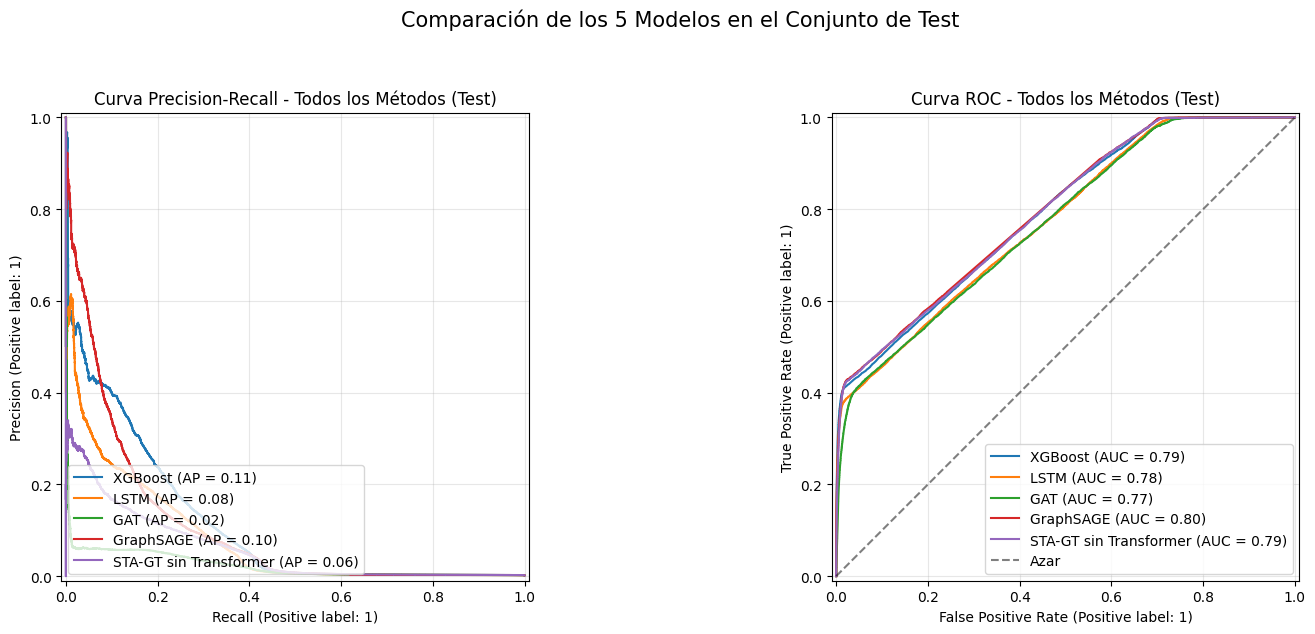

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Lista de modelos y sus scores correspondientes
modelos = [
    ("XGBoost", scores_xgb),
    ("LSTM", scores_lstm),
    ("GAT", scores_gat),
    ("GraphSAGE", scores_sage),
    ("STA-GT sin Transformer", scores_stagt)
]

# Graficar cada modelo en ambas curvas
for nombre, scores in modelos:
    # 1. Curva Precision-Recall
    PrecisionRecallDisplay.from_predictions(
        y_np[test_ids],
        scores[test_ids],
        name=nombre,
        ax=ax1
    )

    # 2. Curva ROC
    RocCurveDisplay.from_predictions(
        y_np[test_ids],
        scores[test_ids],
        name=nombre,
        ax=ax2
    )

# Ajustes del gráfico de Precision-Recall
ax1.set_title("Curva Precision-Recall - Todos los Métodos (Test)")
ax1.grid(alpha=0.3)

# Ajustes del gráfico ROC
ax2.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Azar")
ax2.set_title("Curva ROC - Todos los Métodos (Test)")
ax2.legend()
ax2.grid(alpha=0.3)

plt.suptitle("Comparación de los 5 Modelos en el Conjunto de Test", fontsize=15, y=1.05)
plt.tight_layout()
plt.show()

## **Comparacion de métodos**

In [ ]:
# Los cinco métodos usan las mismas particiones cronológicas; test queda reservado para la evaluación final.
metricas_gat = metricas_desde_scores('GAT', scores_gat)
metricas_sage = metricas_desde_scores('GraphSAGE', scores_sage)
metricas_stagt = metricas_desde_scores('STA-GT sin Transformer', scores_stagt)
metricas_todos = [metricas_xgb, metricas_lstm, metricas_gat, metricas_sage, metricas_stagt]

comparacion_modelos = spark.createDataFrame([
    (
        m['modelo'],
        float(m['AP_val']),
        float(m['AP_test']),
        float(m['ROC_AUC_test']),
        float(m['precision_test']),
        float(m['recall_test']),
        float(m['F1_test']),
        float(m['umbral_val'])
    ) for m in metricas_todos
], ['modelo', 'AP_val', 'AP_test', 'ROC_AUC_test', 'precision_test', 'recall_test', 'F1_test', 'umbral_val'])

comparacion_modelos.orderBy(F.desc('AP_val')).show(truncate=False)

mejor = max(metricas_todos, key=lambda m: m['AP_val'])
print(f"Modelo seleccionado por AP de validacion: {mejor['modelo']} (AP_val={mejor['AP_val']:.5f}); AP_test={mejor['AP_test']:.5f}")

# Cada vector esta alineado por posicion con node_id y cubre todas las transacciones.
if any(np.isnan(scores).any() for scores in (scores_xgb, scores_lstm, scores_gat, scores_sage, scores_stagt)):
    raise RuntimeError('Algun metodo no produjo score para todas las transacciones.')
ruta_scores = 'scores_5_metodos.csv'
with open(ruta_scores, 'w', encoding='utf-8', newline='') as archivo:
    archivo.write('node_id,label,score_xgboost,score_lstm,score_gat,score_graphsage,score_stagt_sin_transformer\n')
    for inicio in range(0, num_nodes, 100_000):
        fin = min(inicio + 100_000, num_nodes)
        bloque = np.column_stack([
            np.arange(inicio, fin, dtype=np.int64), y_np[inicio:fin],
            scores_xgb[inicio:fin], scores_lstm[inicio:fin],
            scores_gat[inicio:fin], scores_sage[inicio:fin], scores_stagt[inicio:fin]
        ])
        np.savetxt(
            archivo, bloque, delimiter=',',
            fmt=['%d', '%d', '%.8f', '%.8f', '%.8f', '%.8f', '%.8f']
        )

print(f'Scores de las {num_nodes:,} transacciones guardados en {ruta_scores}; node_id corresponde a nodos.node_id.')


+----------------------+-------------------+--------------------+------------------+-------------------+-------------------+-------------------+------------------+
|modelo                |AP_val             |AP_test             |ROC_AUC_test      |precision_test     |recall_test        |F1_test            |umbral_val        |
+----------------------+-------------------+--------------------+------------------+-------------------+-------------------+-------------------+------------------+
|XGBoost               |0.12110704811353806|0.11060161856755135 |0.7920793941125366|0.28201989288446827|0.1701126084548643 |0.21221716851862513|0.9626861214637756|
|GraphSAGE             |0.10892500606706605|0.10173418164937442 |0.7957995184324866|0.27178464606181457|0.12580764260660882|0.1719982333270238 |0.9693276286125183|
|LSTM                  |0.08393127069872973|0.07917686564739722 |0.7751083444193417|0.19054106656286493|0.18072733985600886|0.18550450023685458|0.9703773260116577|
|STA-GT sin Tran